# Home Credit Default Risk

**Objective:** To predict the probability of default (PD) for borrowers at Home Credit.

**Dataset:** [Kaggle Home Credit Default Risk](https://www.kaggle.com/c/home-credit-default-risk)
- 307,511 customers, 122 original features
- 6 auxiliary boards: bureau, previous_application, installments_payments, POS_CASH, credit_card, bureau_balance

## 1. Setup and install libraries

In [1]:
import sys, os, json, time, gc, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format='%(asctime)s | %(levelname)s | %(message)s')

PROJ = Path.cwd().resolve()
if PROJ.name == 'notebooks':
    PROJ = PROJ.parent
if str(PROJ) not in sys.path:
    sys.path.insert(0, str(PROJ))
os.chdir(PROJ)

import joblib
from src.config import (
    APP_TRAIN_CSV, MODEL_DIR, RANDOM_STATE, SAMPLE_ROWS,
    TEST_SIZE, VALID_SIZE, TARGET_COL, ID_COL, SCORE_BASE, SCORE_PDO, SCORE_ODDS_BASE,
    MODEL_PATH, METRICS_PATH, DEFAULTS_PATH,
)
MODEL_DIR.mkdir(exist_ok=True)

print(f'Project root: {PROJ}')
print(f'SAMPLE_ROWS: {SAMPLE_ROWS:,}')

Project root: C:\Dev\home-credit-default-risk
SAMPLE_ROWS: 50,000


## 2. Import dataset (chunked + sample)

In [2]:
t0 = time.time()

# Step 1a: read only ID + TARGET to sample (lightweight)
app_ids_df = pd.read_csv(APP_TRAIN_CSV, usecols=[ID_COL, TARGET_COL], low_memory=True)
app_ids_df = app_ids_df.sample(n=min(SAMPLE_ROWS, len(app_ids_df)), random_state=RANDOM_STATE).reset_index(drop=True)
app_ids = set(app_ids_df[ID_COL].tolist())
del app_ids_df; gc.collect()
print(f'Sampled {len(app_ids):,} customers')

# Step 1b: chunked read + filter
def read_filtered(csv_path, ids, chunksize=50_000):
    parts = []
    for chunk in pd.read_csv(csv_path, chunksize=chunksize, low_memory=True):
        filtered = chunk[chunk[ID_COL].isin(ids)]
        if len(filtered) > 0:
            parts.append(filtered)
        del chunk
    out = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    del parts
    return out

def load_aux(name):
    path = PROJ / 'data' / 'raw' / f'{name}.csv'
    if not path.exists():
        print(f'  WARNING: {name}.csv not found'); return pd.DataFrame()
    t = time.time()
    df = read_filtered(path, app_ids)
    print(f'  {name:30s} {len(df):>10,} rows  ({time.time()-t:.1f}s)')
    gc.collect()
    return df

print('\nLoading application_train...')
app = read_filtered(APP_TRAIN_CSV, app_ids)
print(f'application_train: {app.shape}')
gc.collect()

print('\nLoading auxiliary tables...')
bureau       = load_aux('bureau')
gc.collect()
prev_app     = load_aux('previous_application')
gc.collect()
installments = load_aux('installments_payments')
gc.collect()
pos_cash     = load_aux('POS_CASH_balance')
gc.collect()
cc_bal       = load_aux('credit_card_balance')
gc.collect()

print(f'\nTotal load time: {time.time()-t0:.1f}s')
del app_ids

Sampled 50,000 customers

Loading application_train...


application_train: (50000, 122)

Loading auxiliary tables...


  bureau                            237,076 rows  (4.0s)


  previous_application              229,715 rows  (7.6s)


  installments_payments           1,881,881 rows  (15.5s)


  POS_CASH_balance                1,392,087 rows  (10.5s)


  credit_card_balance               520,583 rows  (8.8s)



Total load time: 53.0s


## 3. Exploratory Data Analysis — Target distribution

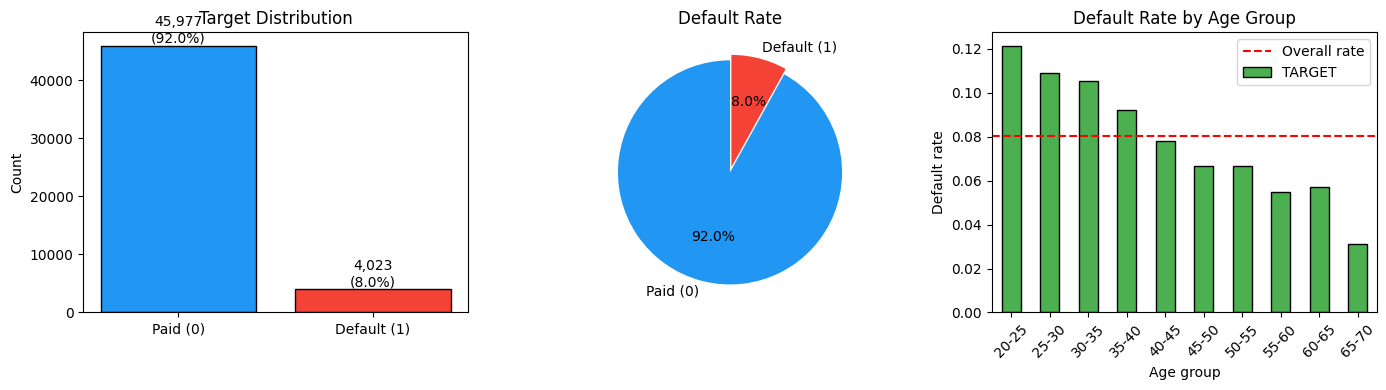


Target stats:
  Total customers : 50,000
  Default (1)     : 4,023  (8.05%)
  Paid (0)        : 45,977  (91.95%)


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 3a. Bar chart
ax = axes[0]
vc = app[TARGET_COL].value_counts()
bars = ax.bar(['Paid (0)', 'Default (1)'], vc.values, color=['#2196F3', '#F44336'], edgecolor='black')
ax.bar_label(bars, [f'{v:,}\n({v/vc.sum()*100:.1f}%)' for v in vc.values], fontsize=10)
ax.set_ylabel('Count'); ax.set_title('Target Distribution')

# 3b. Pie
ax = axes[1]
ax.pie(vc.values, labels=['Paid (0)', 'Default (1)'], autopct='%1.1f%%',
       colors=['#2196F3', '#F44336'], explode=(0, 0.05), startangle=90)
ax.set_title('Default Rate')

# 3c. Default rate by age
ax = axes[2]
app['AGE'] = -app['DAYS_BIRTH'] / 365.25
age_bins = pd.cut(app['AGE'], bins=np.arange(20, 75, 5))
rate_by_age = app.groupby(age_bins)[TARGET_COL].mean()
rate_by_age.index = [f'{int(i.left)}-{int(i.right)}' for i in rate_by_age.index]
rate_by_age.plot(kind='bar', ax=ax, color='#4CAF50', edgecolor='black')
ax.set_xlabel('Age group'); ax.set_ylabel('Default rate')
ax.set_title('Default Rate by Age Group')
ax.tick_params(axis='x', rotation=45)
ax.axhline(app[TARGET_COL].mean(), color='red', ls='--', label='Overall rate')
ax.legend()

plt.tight_layout()
plt.savefig(MODEL_DIR / 'eda_target_distribution.png', dpi=120, bbox_inches='tight')
plt.show()

n_def = int(app[TARGET_COL].sum())
n_paid = int(len(app) - n_def)
print('\nTarget stats:')
print(f'  Total customers : {len(app):,}')
print(f'  Default (1)     : {n_def:,}  ({n_def/len(app)*100:.2f}%)')
print(f'  Paid (0)        : {n_paid:,}  ({n_paid/len(app)*100:.2f}%)')

## 4. Exploratory Data Analysis — Missing values

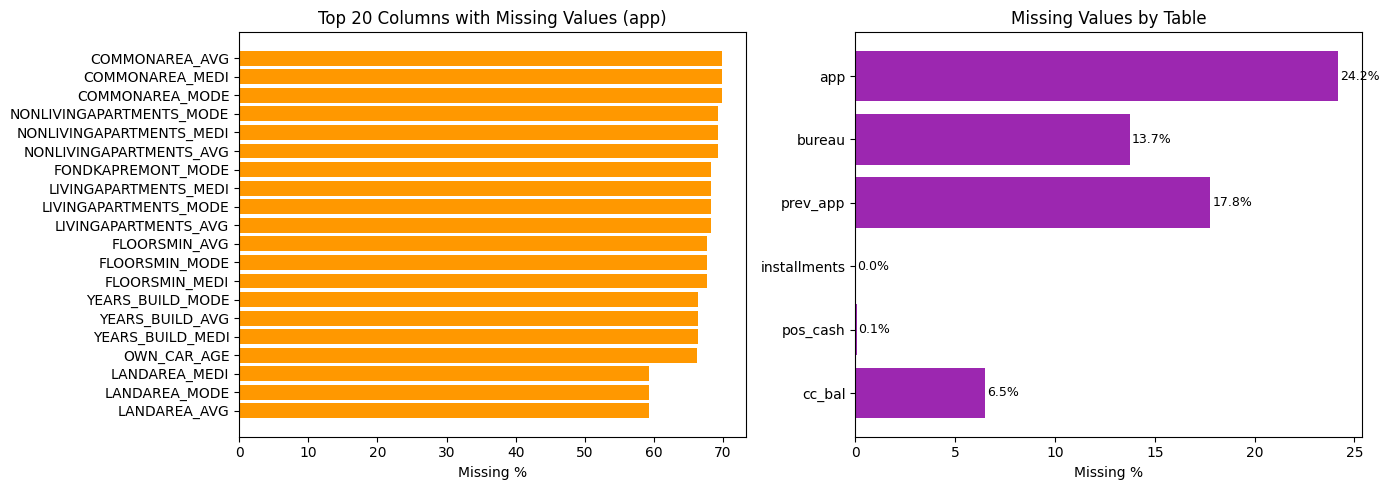


Missing summary:
       table  total_cells  missing_cells  missing_pct
         app      6150000        1486079    24.163886
      bureau      4030292         554048    13.747093
    prev_app      8499455        1510629    17.773245
installments     15055048           1032     0.006855
    pos_cash     11136696           7023     0.063062
      cc_bal     11973409         778573     6.502517

Application columns with >50% missing:
COMMONAREA_AVG              69.780
COMMONAREA_MEDI             69.780
COMMONAREA_MODE             69.780
NONLIVINGAPARTMENTS_MODE    69.262
NONLIVINGAPARTMENTS_MEDI    69.262
NONLIVINGAPARTMENTS_AVG     69.262
FONDKAPREMONT_MODE          68.286
LIVINGAPARTMENTS_MEDI       68.228
LIVINGAPARTMENTS_MODE       68.228
LIVINGAPARTMENTS_AVG        68.228
FLOORSMIN_AVG               67.728
FLOORSMIN_MODE              67.728
FLOORSMIN_MEDI              67.728
YEARS_BUILD_MODE            66.322
YEARS_BUILD_AVG             66.322
YEARS_BUILD_MEDI            66.322
OWN_

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
miss = app.isnull().mean().sort_values(ascending=False)
miss_pct = miss[miss > 0] * 100
top_miss = miss_pct.head(20)
ax.barh(top_miss.index, top_miss.values, color='#FF9800')
ax.set_xlabel('Missing %'); ax.set_title('Top 20 Columns with Missing Values (app)')
ax.invert_yaxis()

ax = axes[1]
tables = {'app': app, 'bureau': bureau, 'prev_app': prev_app,
          'installments': installments, 'pos_cash': pos_cash, 'cc_bal': cc_bal}
miss_summary = []
for name, df in tables.items():
    total = df.shape[0] * df.shape[1]
    n_miss = df.isnull().sum().sum()
    miss_summary.append({'table': name, 'total_cells': total, 'missing_cells': n_miss, 'missing_pct': n_miss/total*100})
miss_df = pd.DataFrame(miss_summary)
ax.barh(miss_df['table'], miss_df['missing_pct'], color='#9C27B0')
ax.set_xlabel('Missing %'); ax.set_title('Missing Values by Table')
ax.invert_yaxis()
for i, v in enumerate(miss_df['missing_pct']):
    ax.text(v + 0.1, i, f'{v:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'eda_missing_values.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nMissing summary:'); print(miss_df.to_string(index=False))
print(f'\nApplication columns with >50% missing:')
print(miss_pct[miss_pct > 50].to_string())

## 5. Exploratory Data Analysis — Key numeric features

2026-10-18 22:41:03,583 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,607 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,658 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,682 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,733 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


...

2026-10-18 22:41:03,829 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,886 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,907 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,958 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 22:41:03,980 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


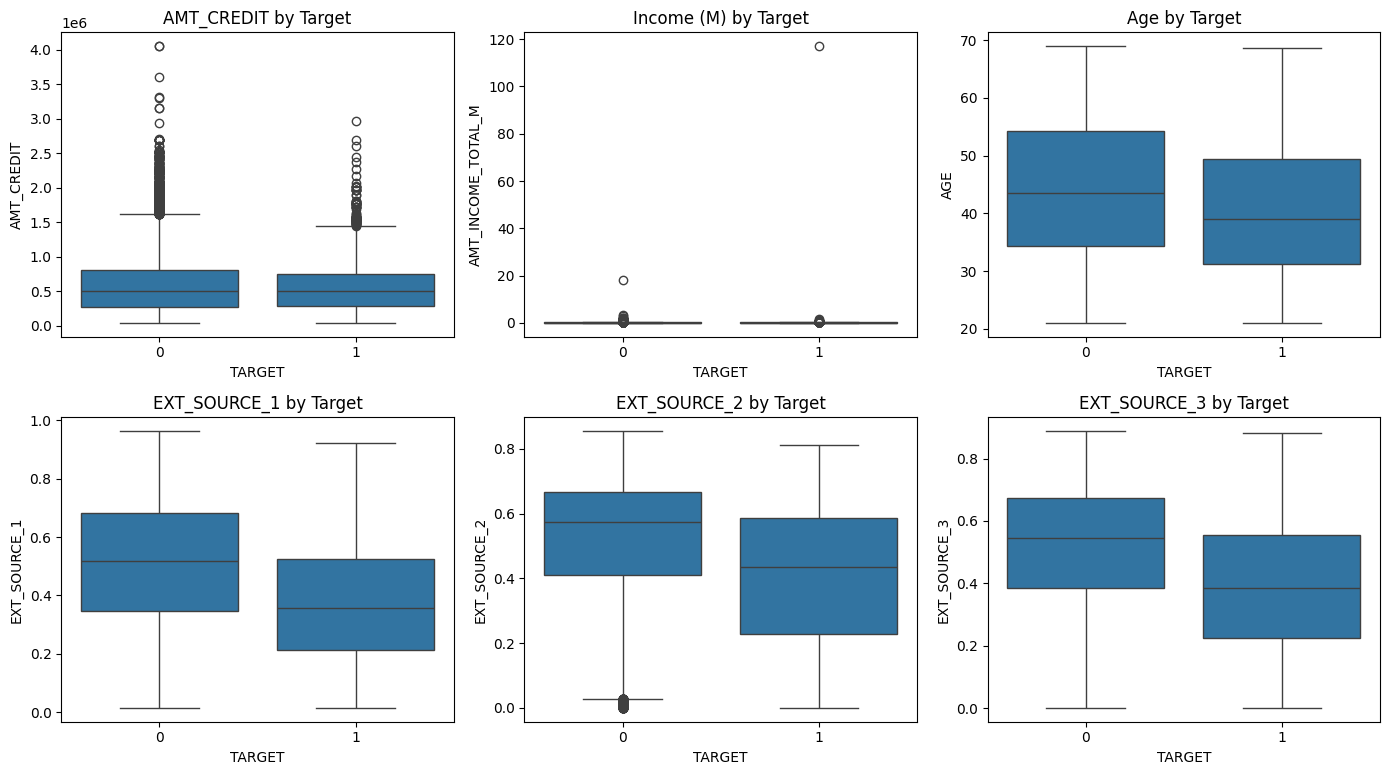


Top 10 positively correlated with TARGET:
FLAG_DOCUMENT_3                0.043427
REG_CITY_NOT_LIVE_CITY         0.044689
FLAG_EMP_PHONE                 0.045345
DAYS_ID_PUBLISH                0.047562
REG_CITY_NOT_WORK_CITY         0.051847
REGION_RATING_CLIENT_W_CITY    0.059882
REGION_RATING_CLIENT           0.061030
DAYS_LAST_PHONE_CHANGE         0.064984
DAYS_BIRTH                     0.079109
FLAG_MOBIL                          NaN

Top 10 negatively correlated with TARGET:
EXT_SOURCE_3                 -0.171603
EXT_SOURCE_2                 -0.168401
EXT_SOURCE_1                 -0.159637
AGE                          -0.079109
DAYS_EMPLOYED                -0.044225
FLOORSMAX_MEDI               -0.043544
FLOORSMAX_AVG                -0.043059
FLOORSMAX_MODE               -0.043050
REGION_POPULATION_RELATIVE   -0.037753
AMT_GOODS_PRICE              -0.036166


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# 5a. AMT_CREDIT
ax = axes[0, 0]
sns.boxplot(data=app, x=TARGET_COL, y='AMT_CREDIT', ax=ax)
ax.set_title('AMT_CREDIT by Target')

# 5b. AMT_INCOME_TOTAL
ax = axes[0, 1]
app['AMT_INCOME_TOTAL_M'] = app['AMT_INCOME_TOTAL'] / 1e6
sns.boxplot(data=app, x=TARGET_COL, y='AMT_INCOME_TOTAL_M', ax=ax)
ax.set_title('Income (M) by Target')

# 5c. AGE
ax = axes[0, 2]
app['AGE'] = -app['DAYS_BIRTH'] / 365.25
sns.boxplot(data=app, x=TARGET_COL, y='AGE', ax=ax)
ax.set_title('Age by Target')

# 5d. EXT_SOURCE_1
ax = axes[1, 0]
sns.boxplot(data=app, x=TARGET_COL, y='EXT_SOURCE_1', ax=ax)
ax.set_title('EXT_SOURCE_1 by Target')

# 5e. EXT_SOURCE_2
ax = axes[1, 1]
sns.boxplot(data=app, x=TARGET_COL, y='EXT_SOURCE_2', ax=ax)
ax.set_title('EXT_SOURCE_2 by Target')

# 5f. EXT_SOURCE_3
ax = axes[1, 2]
sns.boxplot(data=app, x=TARGET_COL, y='EXT_SOURCE_3', ax=ax)
ax.set_title('EXT_SOURCE_3 by Target')

plt.suptitle(''); plt.tight_layout()
plt.savefig(MODEL_DIR / 'eda_key_features.png', dpi=120, bbox_inches='tight')
plt.show()

# Correlation with TARGET
_num_cols_local = app.select_dtypes(include=[np.number]).columns.tolist()
_corr_full = app[_num_cols_local + [TARGET_COL]].corr(numeric_only=True)
_corr_ser = _corr_full[TARGET_COL].drop(TARGET_COL, errors='ignore')
if not isinstance(_corr_ser, pd.Series):
    _corr_ser = _corr_ser.iloc[:, 0] if hasattr(_corr_ser, 'iloc') else pd.Series(_corr_ser)
_corr_sorted = _corr_ser.sort_values()
print('\nTop 10 positively correlated with TARGET:')
print(_corr_sorted.tail(10).to_string())
print('\nTop 10 negatively correlated with TARGET:')
print(_corr_sorted.head(10).to_string())

## 6. Feature Engineering - Application

In [6]:
t0 = time.time()
SENTINEL = 365_243

# Clean: sentinel -> NaN + flag
app['EMPLOYED_ANOM'] = (app['DAYS_EMPLOYED'] == SENTINEL).astype('int8')
app.loc[app['DAYS_EMPLOYED'] == SENTINEL, 'DAYS_EMPLOYED'] = np.nan

# CODE_GENDER XNA -> NaN
if 'CODE_GENDER' in app.columns:
    app.loc[app['CODE_GENDER'] == 'XNA', 'CODE_GENDER'] = np.nan

# OWN_CAR_AGE: no car -> NaN
if {'FLAG_OWN_CAR', 'OWN_CAR_AGE'}.issubset(app.columns):
    app.loc[app['FLAG_OWN_CAR'] == 'N', 'OWN_CAR_AGE'] = np.nan

# Ratio features
income  = app['AMT_INCOME_TOTAL'].replace(0, np.nan)
annuity = app['AMT_ANNUITY'].replace(0, np.nan)
app['CREDIT_INCOME_RATIO']   = app['AMT_CREDIT'] / income
app['ANNUITY_INCOME_RATIO']  = annuity / income
app['CREDIT_TERM']           = app['AMT_CREDIT'] / annuity
app['CREDIT_GOODS_RATIO']   = app['AMT_CREDIT'] / app['AMT_GOODS_PRICE'].replace(0, np.nan)
app['INCOME_PER_FAM']       = income / app['CNT_FAM_MEMBERS'].replace(0, np.nan)
app['INCOME_PER_CHILD']     = income / (app['CNT_CHILDREN'] + 1)

# Time features
app['AGE_YEARS']        = -app['DAYS_BIRTH'] / 365.25
app['EMPLOYED_YEARS']   = -app['DAYS_EMPLOYED'] / 365.25
app['REGISTERED_YEARS'] = -app['DAYS_REGISTRATION'] / 365.25
app['ID_PUBLISH_YEARS'] = -app['DAYS_ID_PUBLISH'] / 365.25

# EXT_SOURCE aggregates (most important group)
ext = app[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']]
app['EXT_SOURCE_MEAN']  = ext.mean(axis=1)
app['EXT_SOURCE_MIN']   = ext.min(axis=1)
app['EXT_SOURCE_MAX']   = ext.max(axis=1)
app['EXT_SOURCE_STD']   = ext.std(axis=1)
app['EXT_SOURCE_PROD'] = ext.prod(axis=1, min_count=2)
app['EXT_SOURCE_COUNT'] = ext.notna().sum(axis=1).astype('int8')

# Document count
doc_cols = [c for c in app.columns if c.startswith('FLAG_DOCUMENT_')]
if doc_cols:
    app['NUM_DOCS_SUBMITTED'] = app[doc_cols].sum(axis=1).astype('int8')

# Drop raw DAYS_*
drop_days = [c for c in app.columns if c.startswith('DAYS_')]
app = app.drop(columns=drop_days)

gc.collect()
print(f'Application features: {app.shape}  ({time.time()-t0:.1f}s)')

Application features: (50000, 137)  (0.2s)


## 7. Feature Engineering — Bureau

In [7]:
t0 = time.time()

keep = [c for c in [
    ID_COL, 'CREDIT_ACTIVE', 'CREDIT_TYPE',
    'DAYS_CREDIT', 'AMT_CREDIT_SUM', 'AMT_CREDIT_SUM_DEBT',
    'AMT_CREDIT_SUM_OVERDUE', 'CREDIT_DAY_OVERDUE', 'CNT_CREDIT_PROLONG',
] if c in bureau.columns]
b = bureau[keep].copy()
del bureau; gc.collect()

b['IS_ACTIVE']  = (b['CREDIT_ACTIVE'] == 'Active').astype('int8')
b['IS_OVERDUE'] = (b['CREDIT_DAY_OVERDUE'] > 0).astype('int8')

type_cts = b.groupby([ID_COL, 'CREDIT_TYPE']).size().unstack(fill_value=0)
type_cts.columns = [f'BUR_TYPE_{c.upper().replace(" ","_")[:20]}' for c in type_cts.columns]

agg = b.groupby(ID_COL).agg(
    BUR_ACTIVE_CNT=('IS_ACTIVE', 'sum'),
    BUR_OVERDUE_CNT=('IS_OVERDUE', 'sum'),
    BUR_CREDIT_SUM=('AMT_CREDIT_SUM', 'sum'),
    BUR_DEBT_SUM=('AMT_CREDIT_SUM_DEBT', 'sum'),
    BUR_OVERDUE_AMT=('AMT_CREDIT_SUM_OVERDUE', 'sum'),
    BUR_MAX_OVERDUE_DAYS=('CREDIT_DAY_OVERDUE', 'max'),
    BUR_PROLONG_CNT=('CNT_CREDIT_PROLONG', 'sum'),
    BUR_LOAN_CNT=(ID_COL, 'count'),
    BUR_DAYS_CREDIT_MIN=('DAYS_CREDIT', 'min'),
)
agg['BUR_DEBT_RATIO'] = agg['BUR_DEBT_SUM'] / agg['BUR_CREDIT_SUM'].replace(0, np.nan)
bureau_feat = agg.join(type_cts, how='left').fillna(0)
bureau_feat['HAS_BUREAU'] = 1

del b, agg, type_cts; gc.collect()
print(f'Bureau features: {bureau_feat.shape}  ({time.time()-t0:.1f}s)')

Bureau features: (42786, 22)  (0.3s)


## 8. Feature Engineering — Previous Application + Installments

In [8]:
t0 = time.time()

# Previous Application
keep_p = [c for c in [
    ID_COL, 'NAME_CONTRACT_STATUS', 'AMT_ANNUITY', 'AMT_APPLICATION', 'AMT_CREDIT',
    'AMT_DOWN_PAYMENT', 'AMT_GOODS_PRICE', 'DAYS_DECISION', 'CNT_PAYMENT',
] if c in prev_app.columns]
p = prev_app[keep_p].copy()
del prev_app; gc.collect()

status_cts = p.groupby([ID_COL, 'NAME_CONTRACT_STATUS']).size().unstack(fill_value=0)
status_cts.columns = [f'PREV_STATUS_{c.upper().replace(" ","_")}' for c in status_cts.columns]
if 'PREV_STATUS_APPROVED' in status_cts.columns and 'PREV_STATUS_REFUSED' in status_cts.columns:
    denom = status_cts['PREV_STATUS_APPROVED'] + status_cts['PREV_STATUS_REFUSED']
    status_cts['PREV_APPROVE_RATE'] = status_cts['PREV_STATUS_APPROVED'] / denom.replace(0, np.nan)

agg_p = p.groupby(ID_COL).agg(
    PREV_CNT=('AMT_ANNUITY', 'count'),
    PREV_AMT_MEAN=('AMT_APPLICATION', 'mean'),
    PREV_AMT_SUM=('AMT_APPLICATION', 'sum'),
    PREV_CREDIT_MAX=('AMT_CREDIT', 'max'),
    PREV_DAYS_DEC_MIN=('DAYS_DECISION', 'min'),
    PREV_CNT_PAYMENT_MEAN=('CNT_PAYMENT', 'mean'),
)
prev_feat = agg_p.join(status_cts, how='left').fillna(0)
prev_feat['HAS_PREV'] = 1
del p, agg_p, status_cts; gc.collect()
print(f'Prev features: {prev_feat.shape}  ({time.time()-t0:.1f}s)')

# Installments Payments
t1 = time.time()
keep_i = [c for c in [
    ID_COL, 'DAYS_INSTALMENT', 'DAYS_ENTRY_PAYMENT', 'AMT_INSTALMENT', 'AMT_PAYMENT',
] if c in installments.columns]
inst = installments[keep_i].copy()
del installments; gc.collect()

inst['LATE_DAYS']   = inst['DAYS_INSTALMENT'] - inst['DAYS_ENTRY_PAYMENT']
inst['LATE_FLAG']   = (inst['LATE_DAYS'] > 0).astype('int8')
inst['LATE_7D']     = (inst['LATE_DAYS'] > 7).astype('int8')
inst['LATE_30D']    = (inst['LATE_DAYS'] > 30).astype('int8')
inst['LATE_60D']    = (inst['LATE_DAYS'] > 60).astype('int8')
inst['UNDERPAID']   = (inst['AMT_PAYMENT'] < inst['AMT_INSTALMENT']).astype('int8')

agg_i = inst.groupby(ID_COL).agg(
    INST_CNT=('AMT_INSTALMENT', 'count'),
    INST_LATE_MAX=('LATE_DAYS', 'max'),
    INST_LATE_MEAN=('LATE_DAYS', 'mean'),
    INST_LATE_7D_SUM=('LATE_7D', 'sum'),
    INST_LATE_30D_SUM=('LATE_30D', 'sum'),
    INST_LATE_60D_SUM=('LATE_60D', 'sum'),
    INST_UNDERPAID_SUM=('UNDERPAID', 'sum'),
)
total_pay = inst.groupby(ID_COL)['AMT_PAYMENT'].sum()
total_due = inst.groupby(ID_COL)['AMT_INSTALMENT'].sum().replace(0, np.nan)
agg_i['INST_PAY_RATIO'] = (total_pay / total_due).fillna(0)
agg_i['HAS_INSTALLMENTS'] = 1
inst_feat = agg_i.fillna(0)
del inst, agg_i, total_pay, total_due; gc.collect()
print(f'Installments features: {inst_feat.shape}  ({time.time()-t1:.1f}s)')
print(f'Feature engineering total: {time.time()-t0:.1f}s')

Prev features: (47320, 12)  (0.3s)


Installments features: (47414, 9)  (0.6s)
Feature engineering total: 0.9s


## 9. Feature Engineering — POS_CASH + Credit Card + Merge all

In [9]:
t0 = time.time()

# POS_CASH
keep_pos = [c for c in [ID_COL, 'MONTHS_BALANCE', 'CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE']
            if c in pos_cash.columns]
pos = pos_cash[keep_pos].copy()
del pos_cash; gc.collect()
pos['POS_UTIL'] = pos['CNT_INSTALMENT_FUTURE'] / pos['CNT_INSTALMENT'].replace(0, np.nan)
pos['MONTHS_BALANCE'] = -pos['MONTHS_BALANCE'] / 12
pos_agg = pos.groupby(ID_COL).agg(
    POS_CNT=('CNT_INSTALMENT', 'count'),
    POS_UTIL_MAX=('POS_UTIL', 'max'),
    POS_UTIL_MEAN=('POS_UTIL', 'mean'),
    POS_MONTHS_MAX=('MONTHS_BALANCE', 'max'),
)
del pos; gc.collect()

# Credit Card
if cc_bal is not None and not cc_bal.empty:
    keep_cc = [c for c in [ID_COL, 'MONTHS_BALANCE', 'AMT_BALANCE', 'AMT_CREDIT_LIMIT_ACTUAL']
              if c in cc_bal.columns]
    cc = cc_bal[keep_cc].copy()
    del cc_bal; gc.collect()
    cc['CC_UTIL'] = (cc['AMT_BALANCE'] / cc['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)).fillna(0)
    cc['MONTHS_BALANCE'] = -cc['MONTHS_BALANCE'] / 12
    cc_agg = cc.groupby(ID_COL).agg(
        CC_CNT=('AMT_BALANCE', 'count'),
        CC_UTIL_MAX=('CC_UTIL', 'max'),
        CC_UTIL_MEAN=('CC_UTIL', 'mean'),
        CC_BALANCE_MAX=('AMT_BALANCE', 'max'),
        CC_MONTHS_MIN=('MONTHS_BALANCE', 'min'),
    )
    del cc; gc.collect()
    pos_cc_feat = pos_agg.join(cc_agg, how='outer').fillna(0)
else:
    pos_cc_feat = pos_agg
del pos_agg; gc.collect()
pos_cc_feat['HAS_POS'] = (pos_cc_feat.get('POS_CNT', 0) > 0).astype('int8')
pos_cc_feat['HAS_CC']  = (pos_cc_feat.get('CC_CNT',  0) > 0).astype('int8')
print(f'POS_CC features: {pos_cc_feat.shape}  ({time.time()-t0:.1f}s)')

# MERGE ALL
t1 = time.time()
def merge_all(app_df, *feats):
    out = app_df.set_index(ID_COL)
    for feat_df in feats:
        if feat_df is not None and not feat_df.empty:
            feat_df = feat_df.add_suffix('_feat')
            out = out.join(feat_df, how='left')
    return out.reset_index()

df_full = merge_all(app, bureau_feat, prev_feat, inst_feat, pos_cc_feat)
del app, bureau_feat, prev_feat, inst_feat, pos_cc_feat; gc.collect()

all_ids = df_full[ID_COL].values.copy()

drop_cols = [ID_COL, 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START']
df_full = df_full.drop(columns=[c for c in drop_cols if c in df_full.columns], errors='ignore')

print(f'\nFull dataset: {df_full.shape}  ({time.time()-t1:.1f}s)')
print(f'  Numeric     : {(df_full.dtypes != object).sum()}')
print(f'  Categorical : {(df_full.dtypes == object).sum()}')
print(f'  Default rate: {df_full[TARGET_COL].mean():.4f}')

POS_CC features: (47521, 11)  (0.7s)



Full dataset: (50000, 188)  (0.5s)
  Numeric     : 173
  Categorical : 15
  Default rate: 0.0805


## 10. Train / Valid / Test split (70/15/15)

In [10]:
from sklearn.model_selection import train_test_split

y_all = df_full[TARGET_COL].values.astype(int)
X_all = df_full.drop(columns=[TARGET_COL])

num_cols = X_all.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_all.select_dtypes(include=['object', 'category']).columns.tolist()
print(f'Numeric: {len(num_cols)}, Categorical: {len(cat_cols)}')

X_tr_val, X_test, y_tr_val, y_test, id_tr_val, X_test_ids = train_test_split(
    X_all, y_all, all_ids,
    test_size=TEST_SIZE, stratify=y_all, random_state=RANDOM_STATE
)
rel = VALID_SIZE / (TEST_SIZE + VALID_SIZE)
X_train, X_valid, y_train, y_valid, _, _ = train_test_split(
    X_tr_val, y_tr_val, id_tr_val,
    test_size=rel, stratify=y_tr_val, random_state=RANDOM_STATE
)
del df_full, X_all, y_all, X_tr_val, y_tr_val; gc.collect()

print(f'\nTrain : {len(X_train):,}  ({y_train.mean():.2%} default)')
print(f'Valid : {len(X_valid):,}  ({y_valid.mean():.2%} default)')
print(f'Test  : {len(X_test):,}  ({y_test.mean():.2%} default)')

Numeric: 172, Categorical: 15



Train : 21,250  (8.05% default)
Valid : 21,250  (8.05% default)
Test  : 7,500  (8.04% default)


## 11. Preprocessing (impute + scale + one-hot encode)

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipe_scaled = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  StandardScaler()),
])
num_pipe_raw = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
])

cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('ohe',    OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

ct_scaled = ColumnTransformer([
    ('num', num_pipe_scaled, num_cols),
    ('cat', cat_pipe, cat_cols),
], remainder='drop', verbose_feature_names_out=False)

ct_raw = ColumnTransformer([
    ('num', num_pipe_raw, num_cols),
    ('cat', cat_pipe, cat_cols),
], remainder='drop', verbose_feature_names_out=False)

ct_scaled.fit(X_train)
ct_raw.fit(X_train)

X_tr_s = ct_scaled.transform(X_train)
X_va_s = ct_scaled.transform(X_valid)
X_te_s = ct_scaled.transform(X_test)

X_tr_r = ct_raw.transform(X_train)
X_va_r = ct_raw.transform(X_valid)
X_te_r = ct_raw.transform(X_test)

_cat_ohe = ct_scaled.named_transformers_['cat'].named_steps['ohe']
_cat_names = [f'cat__{n}' for n in _cat_ohe.get_feature_names_out(cat_cols)]
feature_names = [f'num__{n}' for n in num_cols] + _cat_names
print(f'Features after encoding: {len(feature_names)}')
print(f'X_tr_s: {X_tr_s.shape}   (scaled, for Logistic)')
print(f'X_tr_r: {X_tr_r.shape}   (raw, for LightGBM)')

Features after encoding: 301
X_tr_s: (21250, 301)   (scaled, for Logistic)
X_tr_r: (21250, 301)   (raw, for LightGBM)


## 12. Baseline: Logistic Regression (2 variants)

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss, precision_recall_curve

def mscore(y, p):
    auc = roc_auc_score(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    return dict(auc=auc, gini=2*auc-1, ks=float(np.max(np.abs(tpr - fpr))),
                brier=brier_score_loss(y, p), pr_auc=average_precision_score(y, p))

# Logistic (no weight)
lr = LogisticRegression(C=0.5, max_iter=2000, solver='liblinear', random_state=RANDOM_STATE)
lr.fit(X_tr_s, y_train)
lr_prob = lr.predict_proba(X_va_s)[:, 1]
lr_m = mscore(y_valid, lr_prob)
print(f'Logistic (class_weight=None)  | AUC={lr_m["auc"]:.4f} | KS={lr_m["ks"]:.4f} | Brier={lr_m["brier"]:.4f}')

# Logistic (balanced)
lr_b = LogisticRegression(C=0.5, max_iter=2000, class_weight='balanced', solver='liblinear', random_state=RANDOM_STATE)
lr_b.fit(X_tr_s, y_train)
lr_b_prob = lr_b.predict_proba(X_va_s)[:, 1]
lr_b_m = mscore(y_valid, lr_b_prob)
print(f'Logistic (class_weight=balanced) | AUC={lr_b_m["auc"]:.4f} | KS={lr_b_m["ks"]:.4f} | Brier={lr_b_m["brier"]:.4f}')

Logistic (class_weight=None)  | AUC=0.7533 | KS=0.3786 | Brier=0.0685


Logistic (class_weight=balanced) | AUC=0.7495 | KS=0.3710 | Brier=0.1939


## 13. LightGBM + Optuna hyperparameter tuning (15 trials)

In [13]:
import lightgbm as lgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        'objective': 'binary', 'metric': 'auc',
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.08, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 15, 63),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'min_child_samples': trial.suggest_int('min_child_samples', 30, 200),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 5.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 5.0, log=True),
        'scale_pos_weight': 1.0,
        'random_state': RANDOM_STATE,
        'num_threads': 1, 'verbose': -1,
        'max_bin': 63, 'min_data_in_bin': 50,
    }
    dtrain = lgb.Dataset(X_tr_r, label=y_train, free_raw_data=False)
    dvalid = lgb.Dataset(X_va_r, label=y_valid, reference=dtrain, free_raw_data=False)
    booster = lgb.train(
        params, dtrain, num_boost_round=400,
        valid_sets=[dvalid],
        callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)],
    )
    prob = booster.predict(X_va_r, num_iteration=booster.best_iteration)
    return roc_auc_score(y_valid, prob)

t0 = time.time()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=15, timeout=300, show_progress_bar=False)
print(f'Optuna done in {time.time()-t0:.1f}s — best AUC={study.best_value:.4f}')
print(f'Best params: {study.best_params}')

Optuna done in 35.2s — best AUC=0.7633
Best params: {'learning_rate': 0.04692376031091254, 'num_leaves': 53, 'max_depth': 4, 'min_child_samples': 117, 'subsample': 0.836965827544817, 'colsample_bytree': 0.5232252063599989, 'reg_alpha': 0.1767218232266506, 'reg_lambda': 0.0042733023193754}


## 14. Final LightGBM (best params, early stop)

In [14]:
best_params = study.best_params | {
    'objective': 'binary', 'metric': 'auc',
    'scale_pos_weight': 1.0, 'random_state': RANDOM_STATE,
    'num_threads': 1, 'verbose': -1,
    'max_bin': 63, 'min_data_in_bin': 50,
}

lgb_model = lgb.LGBMClassifier(n_estimators=2000, **best_params)
lgb_model.fit(
    X_tr_r, y_train,
    eval_set=[(X_va_r, y_valid)],
    eval_metric='binary_logloss',
    callbacks=[lgb.early_stopping(150, verbose=False), lgb.log_evaluation(200)],
)
best_iter = int(lgb_model.best_iteration_ or lgb_model.n_estimators)
lgb_prob = lgb_model.predict_proba(X_va_r)[:, 1]
lgb_m = mscore(y_valid, lgb_prob)
print(f'\nLightGBM (tuned) | AUC={lgb_m["auc"]:.4f} | KS={lgb_m["ks"]:.4f} | Brier={lgb_m["brier"]:.4f} | best_iter={best_iter}')

[200]	valid_0's binary_logloss: 0.243699	valid_0's auc: 0.763057



LightGBM (tuned) | AUC=0.7633 | KS=0.3945 | Brier=0.0671 | best_iter=187


## 15. Calibration (Isotonic Regression)

In [15]:
from sklearn.isotonic import IsotonicRegression

def ece_score(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob < bins[i+1])
        if mask.sum() > 0:
            ece += mask.mean() * abs(y_true[mask].mean() - (bins[i]+bins[i+1])/2)
    return ece

brier = lgb_m['brier']
ece = ece_score(y_valid, lgb_prob)
print(f'Pre-calibration: Brier={brier:.4f}, ECE={ece:.4f}')

iso_reg = IsotonicRegression(out_of_bounds='clip', y_min=0.001, y_max=0.999)
iso_reg.fit(lgb_prob, y_valid)
lgb_prob_cal = iso_reg.predict(lgb_prob)
lgb_cal_m = mscore(y_valid, lgb_prob_cal)
print(f'Post-calibration: Brier={lgb_cal_m["brier"]:.4f}, ECE={ece_score(y_valid, lgb_prob_cal):.4f}')
print(f'LightGBM (calibrated) | AUC={lgb_cal_m["auc"]:.4f} | KS={lgb_cal_m["ks"]:.4f}')

Pre-calibration: Brier=0.0671, ECE=0.0089
Post-calibration: Brier=0.0668, ECE=0.0053
LightGBM (calibrated) | AUC=0.7658 | KS=0.3945


## 16. Threshold tuning (F1-driven, recall >= 80%)

In [16]:
from sklearn.metrics import f1_score, recall_score, precision_score

def find_best_threshold(y_true, y_prob, min_recall=0.80):
    best_f1, best_thr = -1.0, 0.5
    for thr in np.linspace(0.01, 0.99, 99):
        yp = (y_prob >= thr).astype(int)
        rec = recall_score(y_true, yp, zero_division=0)
        f1  = f1_score(y_true, yp, zero_division=0)
        if rec >= min_recall and f1 > best_f1:
            best_f1, best_thr = f1, thr
    yp = (y_prob >= best_thr).astype(int)
    return {
        'threshold': best_thr,
        'f1': best_f1,
        'recall': recall_score(y_true, yp),
        'precision': precision_score(y_true, yp),
    }

thr_info = find_best_threshold(y_valid, lgb_prob)
best_thr = thr_info['threshold']
print(f'Best threshold: {best_thr:.3f}')
print(f'  F1={thr_info["f1"]:.4f}  Recall={thr_info["recall"]:.4f}  Precision={thr_info["precision"]:.4f}')

Best threshold: 0.050
  F1=0.2254  Recall=0.8322  Precision=0.1304


## 17. Final evaluation on TEST set

In [17]:
lr_te     = lr.predict_proba(X_te_s)[:, 1]
lr_b_te   = lr_b.predict_proba(X_te_s)[:, 1]
lgb_te    = lgb_model.predict_proba(X_te_r)[:, 1]
lgb_cal_te = iso_reg.predict(lgb_te)

results = {}
for name, prob in [('Logistic', lr_te), ('Logistic_balanced', lr_b_te),
                    ('LightGBM', lgb_te), ('LightGBM_calibrated', lgb_cal_te)]:
    m = mscore(y_test, prob)
    yp = (prob >= best_thr).astype(int)
    results[name] = {**m,
                     'test_f1': f1_score(y_test, yp),
                     'test_recall': recall_score(y_test, yp),
                     'test_precision': precision_score(y_test, yp),
                     'threshold': best_thr}

summary = []
for name, m in results.items():
    summary.append({'model': name, **m})
summary_df = pd.DataFrame(summary).set_index('model').round(4)
print('\n' + '='*70)
print('METRICS ON TEST SET')
print('='*70)
cols = ['auc', 'gini', 'ks', 'brier', 'pr_auc', 'test_f1', 'test_recall', 'test_precision', 'threshold']
print(summary_df[cols].to_string())

summary_df.reset_index().to_csv(MODEL_DIR / 'metrics_table.csv', index=False)
print(f'\nSaved: {MODEL_DIR / "metrics_table.csv"}')


METRICS ON TEST SET
                        auc    gini      ks   brier  pr_auc  test_f1  test_recall  test_precision  threshold
model                                                                                                       
Logistic             0.7452  0.4904  0.3689  0.0684  0.2350   0.2248       0.7927          0.1310       0.05
Logistic_balanced    0.7412  0.4823  0.3626  0.1940  0.2288   0.1535       1.0000          0.0831       0.05
LightGBM             0.7594  0.5188  0.3858  0.0677  0.2365   0.2294       0.8375          0.1329       0.05
LightGBM_calibrated  0.7582  0.5164  0.3751  0.0678  0.2282   0.2232       0.8624          0.1282       0.05

Saved: C:\Dev\home-credit-default-risk\model\metrics_table.csv


## 18. Evaluation plots — ROC / PR / KS / Calibration

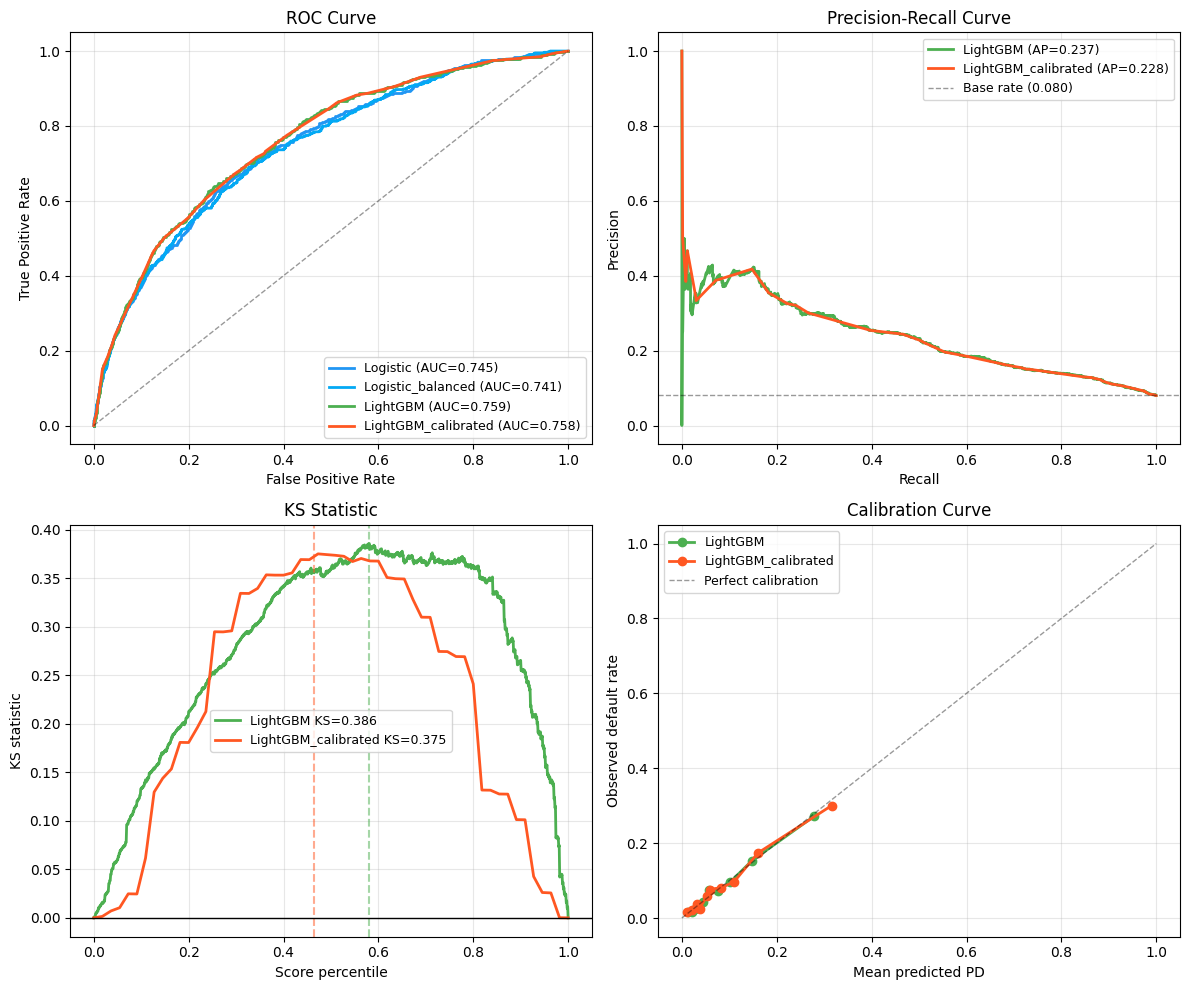

Saved: C:\Dev\home-credit-default-risk\model\evaluation_curves.png


In [18]:
from sklearn.calibration import calibration_curve as sk_cal_curve

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
colors = {'Logistic':'#2196F3', 'Logistic_balanced':'#03A9F4',
          'LightGBM':'#4CAF50', 'LightGBM_calibrated':'#FF5722'}

# ROC
ax = axes[0, 0]
for name, prob in [('Logistic', lr_te), ('Logistic_balanced', lr_b_te),
                    ('LightGBM', lgb_te), ('LightGBM_calibrated', lgb_cal_te)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, color=colors[name], lw=2, label=f'{name} (AUC={auc:.3f})')
ax.plot([0,1],[0,1], 'k--', lw=1, alpha=0.4)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve'); ax.legend(fontsize=9); ax.grid(alpha=0.3)

# PR Curve
ax = axes[0, 1]
for name, prob in [('LightGBM', lgb_te), ('LightGBM_calibrated', lgb_cal_te)]:
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    ax.plot(rec, prec, color=colors[name], lw=2, label=f'{name} (AP={ap:.3f})')
ax.axhline(y_test.mean(), color='k', ls='--', lw=1, alpha=0.4, label=f'Base rate ({y_test.mean():.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve'); ax.legend(fontsize=9); ax.grid(alpha=0.3)

# KS Plot
ax = axes[1, 0]
for name, prob, c in [('LightGBM', lgb_te, '#4CAF50'),
                        ('LightGBM_calibrated', lgb_cal_te, '#FF5722')]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ks_vals = tpr - fpr
    ks = np.max(np.abs(ks_vals))
    ks_idx = np.argmax(np.abs(ks_vals))
    pct_idx = ks_idx / len(fpr)
    ax.plot(np.linspace(0,1,len(fpr)), ks_vals, color=c, lw=2, label=f'{name} KS={ks:.3f}')
    ax.axvline(pct_idx, color=c, ls='--', alpha=0.5)
ax.axhline(0, color='k', lw=1)
ax.set_xlabel('Score percentile'); ax.set_ylabel('KS statistic')
ax.set_title('KS Statistic'); ax.legend(fontsize=9); ax.grid(alpha=0.3)

# Calibration
ax = axes[1, 1]
for name, prob, c in [('LightGBM', lgb_te, '#4CAF50'),
                        ('LightGBM_calibrated', lgb_cal_te, '#FF5722')]:
    frac, mean_p = sk_cal_curve(y_test, prob, n_bins=10, strategy='quantile')
    ax.plot(mean_p, frac, 'o-', color=c, lw=2, label=name)
ax.plot([0,1],[0,1], 'k--', lw=1, alpha=0.4, label='Perfect calibration')
ax.set_xlabel('Mean predicted PD'); ax.set_ylabel('Observed default rate')
ax.set_title('Calibration Curve'); ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(MODEL_DIR / 'evaluation_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved: {MODEL_DIR / "evaluation_curves.png"}')

## 19. Feature Importance (LightGBM — top 25)

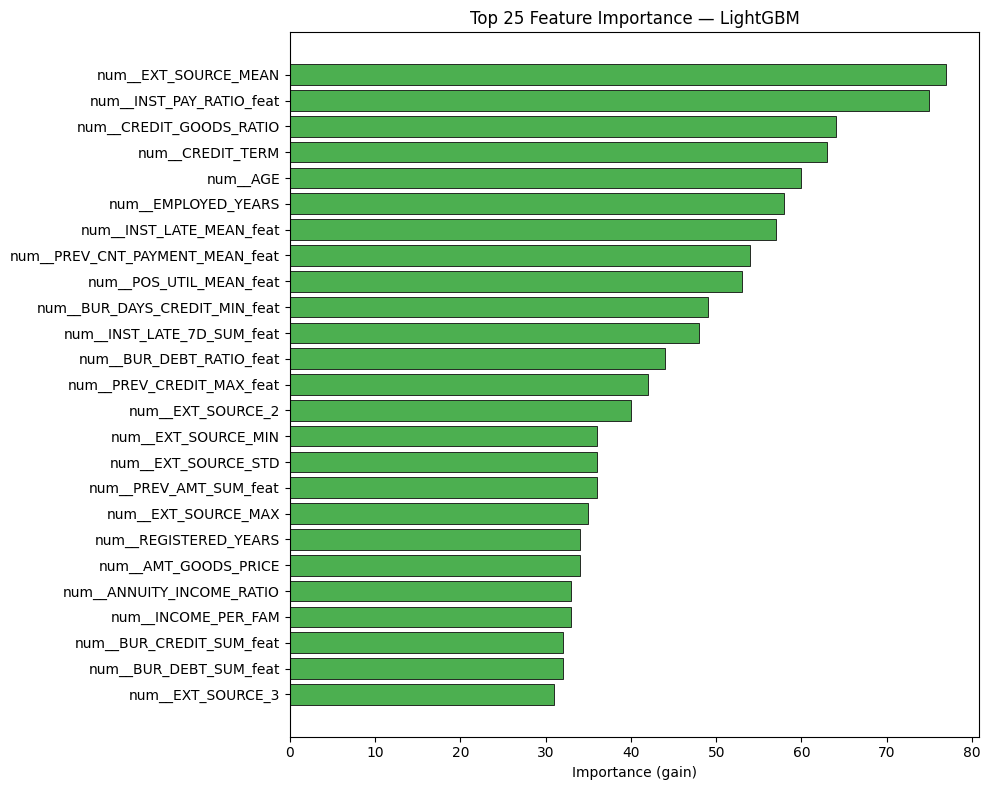


Top 15 features:
                        feature  importance
           num__EXT_SOURCE_MEAN          77
       num__INST_PAY_RATIO_feat          75
        num__CREDIT_GOODS_RATIO          64
               num__CREDIT_TERM          63
                       num__AGE          60
            num__EMPLOYED_YEARS          58
       num__INST_LATE_MEAN_feat          57
num__PREV_CNT_PAYMENT_MEAN_feat          54
        num__POS_UTIL_MEAN_feat          53
  num__BUR_DAYS_CREDIT_MIN_feat          49
     num__INST_LATE_7D_SUM_feat          48
       num__BUR_DEBT_RATIO_feat          44
      num__PREV_CREDIT_MAX_feat          42
              num__EXT_SOURCE_2          40
            num__EXT_SOURCE_STD          36

Saved: C:\Dev\home-credit-default-risk\model\feature_importance.png


In [19]:
imp = lgb_model.feature_importances_
fi_df = pd.DataFrame({'feature': feature_names[:len(imp)], 'importance': imp}).sort_values('importance', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 8))
top = fi_df.head(25).sort_values('importance', ascending=True)
ax.barh(top['feature'], top['importance'], color='#4CAF50', edgecolor='#0F0F0F', linewidth=0.6)
ax.set_xlabel('Importance (gain)'); ax.set_title('Top 25 Feature Importance — LightGBM')
fig.tight_layout()
plt.savefig(MODEL_DIR / 'feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nTop 15 features:')
print(fi_df.head(15).to_string(index=False))
print(f'\nSaved: {MODEL_DIR / "feature_importance.png"}')

## 20. Save model artifact (đồng bộ với app/streamlit_app.py)

In [20]:
X_full = np.vstack([X_tr_r, X_va_r])
y_full = np.concatenate([y_train, y_valid])
n_final = int(best_iter * 1.1)
lgb_final = lgb.LGBMClassifier(n_estimators=n_final, **best_params)
lgb_final.fit(X_full, y_full)

ct_raw_save = ct_raw

artifact = {
    'ct':              ct_raw_save,
    'lgb':             lgb_final,
    'iso_reg':         iso_reg,
    'num_cols':        num_cols,
    'cat_cols':        cat_cols,
    'feature_names':   feature_names,
    'best_threshold':  float(best_thr),
    'score_base':      SCORE_BASE,
    'score_pdo':       SCORE_PDO,
    'score_odds_base': SCORE_ODDS_BASE,
    'model_name':      'LightGBM_calibrated',
}

joblib.dump(artifact, MODEL_PATH, compress=3)
size_mb = MODEL_PATH.stat().st_size / 1024 / 1024
print('Saved:', MODEL_PATH, '({:.2f} MB)'.format(size_mb))

METRICS_PATH.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved:', METRICS_PATH)

DEFAULTS_PATH.write_text(json.dumps({
    'model_name':      'LightGBM_calibrated',
    'best_threshold':  float(best_thr),
    'score_base':      SCORE_BASE,
    'score_pdo':       SCORE_PDO,
    'score_odds_base': SCORE_ODDS_BASE,
    'test_metrics':    {k: float(v) if isinstance(v, (np.floating, float)) else v
                        for k, v in results['LightGBM_calibrated'].items()},
}, indent=2, ensure_ascii=False), encoding='utf-8')
print('Saved:', DEFAULTS_PATH)

Saved: C:\Dev\home-credit-default-risk\model\model.joblib (0.16 MB)
Saved: C:\Dev\home-credit-default-risk\model\metrics.json
Saved: C:\Dev\home-credit-default-risk\model\defaults.json


## 21. Test Predictions + Smoke test

In [21]:
print('\n--- Test Set Predictions ---')
test_pred_df = pd.DataFrame({
    'SK_ID_CURR':  X_test_ids,
    'y_true':      y_test,
    'y_proba_raw': lgb_te,
    'y_proba':     lgb_cal_te,
    'y_pred':      (lgb_cal_te >= best_thr).astype(int),
})
print('Test samples: {:,}'.format(len(test_pred_df)))
print('Defaults predicted: {:,} ({:.2f}%)'.format(
    test_pred_df['y_pred'].sum(), test_pred_df['y_pred'].mean()*100))

def pd_to_rating(pd_val):
    if pd_val < 0.03: return 'A'
    elif pd_val < 0.06: return 'B'
    elif pd_val < 0.10: return 'C'
    elif pd_val < 0.20: return 'D'
    else: return 'E'

test_pred_df['rating'] = test_pred_df['y_proba'].apply(pd_to_rating)
print('\nRating distribution:')
print(test_pred_df['rating'].value_counts().sort_index())

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, test_pred_df['y_pred'])
print('\nConfusion Matrix (threshold={:.3f}):'.format(best_thr))
print('             Predicted')
print('             No    Yes')
print('Actual No  {:5d}  {:5d}'.format(cm[0,0], cm[0,1]))
print('       Yes {:5d}  {:5d}'.format(cm[1,0], cm[1,1]))

pred_path = MODEL_DIR / 'predictions_test.csv'
test_pred_df.to_csv(pred_path, index=False)
print('\nSaved predictions:', pred_path)

# Smoke test
print('\n--- Reload Smoke Test ---')
loaded = joblib.load(MODEL_PATH)
print('  keys        =', list(loaded.keys()))
print('  threshold   =', loaded['best_threshold'])
print('  n_features  =', len(loaded['feature_names']))
print('  model_name  =', loaded['model_name'])

sample_X = pd.DataFrame([{
    'AMT_CREDIT': 500000, 'AMT_INCOME_TOTAL': 200000,
    'AMT_ANNUITY': 30000, 'AMT_GOODS_PRICE': 450000,
    'NAME_CONTRACT_TYPE': 'Cash loans', 'CODE_GENDER': 'M',
    'DAYS_BIRTH': -14000, 'DAYS_EMPLOYED': -3000,
    'CNT_FAM_MEMBERS': 2, 'EXT_SOURCE_1': 0.6,
    'EXT_SOURCE_2': 0.5, 'EXT_SOURCE_3': 0.4,
}])
for c in loaded['num_cols']:
    if c not in sample_X.columns: sample_X[c] = np.nan
for c in loaded['cat_cols']:
    if c not in sample_X.columns: sample_X[c] = 'Unknown'

X_sample = loaded['ct'].transform(sample_X)
raw_p  = float(loaded['lgb'].predict_proba(X_sample)[:, 1][0])
cal_p  = float(loaded['iso_reg'].predict([raw_p])[0])
decision = 'APPROVE' if cal_p < loaded['best_threshold'] else 'REJECT'
print('  Sample: raw_p={:.4f}, cal_p={:.4f}'.format(raw_p, cal_p))
print('  Decision @thr={:.3f}: {}'.format(loaded['best_threshold'], decision))


--- Test Set Predictions ---
Test samples: 7,500
Defaults predicted: 4,057 (54.09%)

Rating distribution:
rating
A    2185
B    2372
C    1241
D    1166
E     536
Name: count, dtype: int64

Confusion Matrix (threshold=0.050):
             Predicted
             No    Yes
Actual No   3360   3537
       Yes    83    520

Saved predictions: C:\Dev\home-credit-default-risk\model\predictions_test.csv

--- Reload Smoke Test ---
  keys        = ['ct', 'lgb', 'iso_reg', 'num_cols', 'cat_cols', 'feature_names', 'best_threshold', 'score_base', 'score_pdo', 'score_odds_base', 'model_name']
  threshold   = 0.05
  n_features  = 301
  model_name  = LightGBM_calibrated
  Sample: raw_p=0.0595, cal_p=0.0567
  Decision @thr=0.050: REJECT


## 22. Kết quả tổng hợp

In [22]:
print('='*70)
print('FINAL RESULTS — TEST SET')
print('='*70)
disp = summary_df[['auc', 'gini', 'ks', 'brier', 'pr_auc', 'test_f1', 'test_recall', 'test_precision']].round(4)
disp.columns = ['AUC', 'Gini', 'KS', 'Brier', 'PR-AUC', 'F1', 'Recall', 'Precision']
disp = disp.sort_values('AUC', ascending=False)
print(disp.to_string())

print(f'\nBest model : {disp.index[0]}')
print(f'Threshold  : {best_thr:.3f}')
print(f'Features   : {len(feature_names)}')
print(f'Best iter  : {best_iter}')
print(f'Artifacts  : {MODEL_DIR}')
print('\nSaved files:')
for p in sorted(MODEL_DIR.iterdir()):
    if p.is_file() and not p.name.endswith('.broken'):
        print(f'  {p.name:40s}  {p.stat().st_size/1024:>8.1f} KB')

FINAL RESULTS — TEST SET
                        AUC    Gini      KS   Brier  PR-AUC      F1  Recall  Precision
model                                                                                 
LightGBM             0.7594  0.5188  0.3858  0.0677  0.2365  0.2294  0.8375     0.1329
LightGBM_calibrated  0.7582  0.5164  0.3751  0.0678  0.2282  0.2232  0.8624     0.1282
Logistic             0.7452  0.4904  0.3689  0.0684  0.2350  0.2248  0.7927     0.1310
Logistic_balanced    0.7412  0.4823  0.3626  0.1940  0.2288  0.1535  1.0000     0.0831

Best model : LightGBM
Threshold  : 0.050
Features   : 301
Best iter  : 187
Artifacts  : C:\Dev\home-credit-default-risk\model

Saved files:
  defaults.json                                  0.5 KB
  eda_key_features.png                          65.8 KB
  eda_missing_values.png                        85.2 KB
  eda_target_distribution.png                   61.1 KB
  evaluation_curves.png                        185.6 KB
  feature_importance.png        